# **Praktik 1**

=== [1/6] Menginstal library & mendownload resource NLTK... ===

=== [2/6] Mengunduh ratusan artikel dari Wikipedia secara otomatis... ===
✓ Berhasil mengumpulkan total 60 artikel Wikipedia.

=== [3/6] Menjalankan Clustering pada Dataset Besar... ===


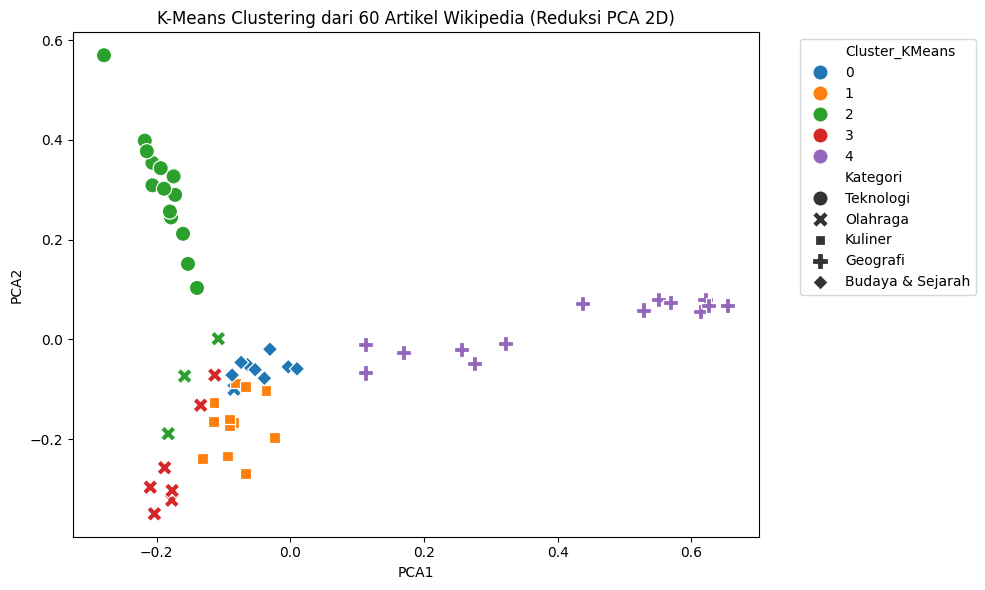


=== [4/6] Menjalankan Topic Modeling (LDA) untuk Ratusan Artikel... ===

Topik Utama Tersembunyi (Top 7 Kata per Topik):
Topik #1: bola, permainan, sistem, tenis, pangkalan, operasi, data
Topik #2: pemelajaran, bola, catur, gudeg, bubur, rendang, masakan
Topik #3: sate, keamanan, data, batik, meja, goreng, nasi
Topik #4: internet, pempek, berenang, era, bakso, jejaring, komputer
Topik #5: kota, indonesia, provinsi, pulau, barat, jakarta, bahasa

=== [5/6] Menjalankan Word Embeddings (Word2Vec)... ===


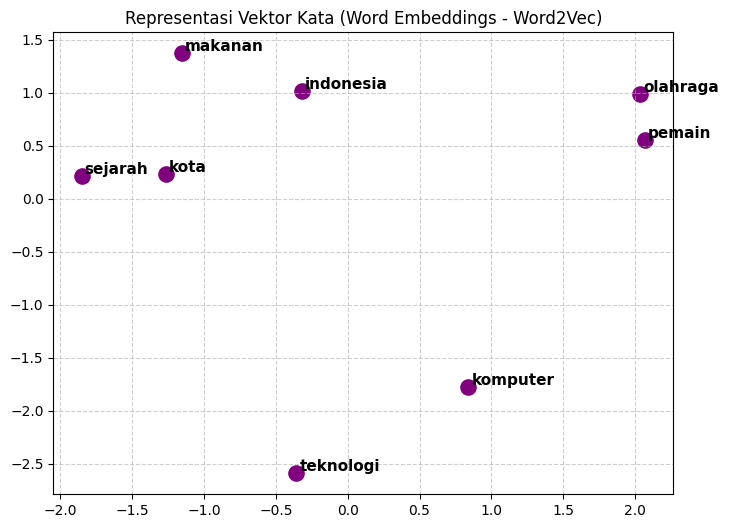


=== [6/6] Menjalankan Deep Learning / Neural Network (Autoencoder)... ===
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step


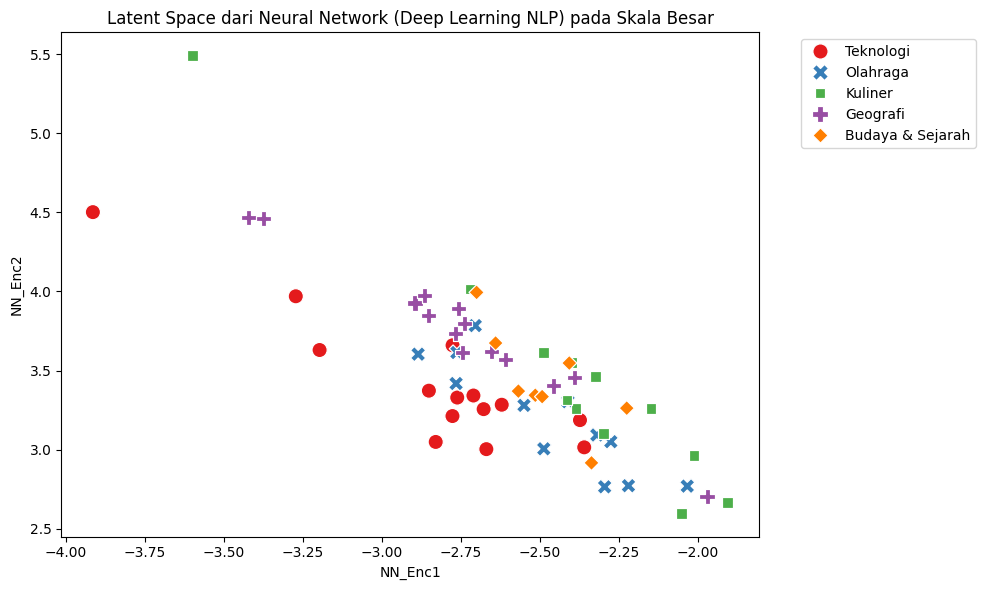


=== PRAKTIKUM SKALA BESAR SELESAI DAN BERHASIL DIJALANKAN! ===


In [ ]:
# ==============================================================================
# PRAKTIKUM NLP & UNSUPERVISED LEARNING: RATUSAN ARTIKEL WIKIPEDIA
# ==============================================================================

import sys
import subprocess

# 1. OTOMATISASI INSTALLASI LIBRARY & DOWNLOAD NLTK DATA
print("=== [1/6] Menginstal library & mendownload resource NLTK... ===")
required_packages = ['wikipedia-api', 'scikit-learn', 'gensim', 'tensorflow', 'matplotlib', 'seaborn', 'nltk']

for package in required_packages:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

import nltk
nltk.download('punkt', quiet=True)
try:
    nltk.download('punkt_tab', quiet=True)
except:
    pass
nltk.download('stopwords', quiet=True)

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 2. OTOMATISASI DOWNLOAD RATUSAN ARTIKEL DARI WIKIPEDIA
print("\n=== [2/6] Mengunduh ratusan artikel dari Wikipedia secara otomatis... ===")
import wikipediaapi

wiki = wikipediaapi.Wikipedia(user_agent='NLPPraktikumBotLarge/1.0 (contact@example.com)', language='id')

# Daftar topik induk yang luas untuk memperbanyak variasi artikel
base_topics = [
    # Teknologi & Sains
    'Kecerdasan buatan', 'Pembelajaran mesin', 'Pembelajaran dalam', 'Pemrosesan bahasa alami',
    'Ilmu komputer', 'Algoritma', 'Basis data', 'Keamanan siber', 'Jaringan komputer',
    'Sistem operasi', 'Komputasi awan', 'Mahadata', 'Internet untuk Segala', 'Realitas virtual',
    # Olahraga
    'Sepak bola', 'Bola basket', 'Bulutangkis', 'Renang', 'Bola voli', 'Tenis',
    'Pencak silat', 'Catur', 'Tinju', 'Formula Satu', 'Atletik', 'Tenis meja',
    # Kuliner & Makanan
    'Masakan Indonesia', 'Rendang', 'Nasi goreng', 'Sate', 'Gado-gado', 'Soto',
    'Bakso', 'Pempek', 'Nasi padang', 'Bubur ayam', 'Martabak', 'Gudeg',
    # Geografi & Tempat di Indonesia
    'Jakarta', 'Surabaya', 'Bandung', 'Medan', 'Semarang', 'Makassar', 'Palembang',
    'Yogyakarta', 'Pekanbaru', 'Riau', 'Sumatera Barat', 'Bali', 'Kalimantan', 'Papua',
    # Sejarah & Tokoh / Budaya
    'Sejarah Indonesia', 'Proklamasi Kemerdekaan Indonesia', 'Bhinneka Tunggal Ika',
    'Pancasila', 'Batik', 'Wayang', 'Gamelan', 'Bahasa Indonesia'
]

corpus = []
labels_true = []
titles_collected = []

for topic in base_topics:
    page = wiki.page(topic)
    if page.exists():
        text = page.summary
        if len(text.strip()) > 100: # Pastikan artikel memiliki isi yang cukup
            corpus.append(text)
            titles_collected.append(topic)

            # Kategorisasi otomatis berdasarkan kata kunci induk
            if topic in ['Kecerdasan buatan', 'Pembelajaran mesin', 'Pembelajaran dalam', 'Pemrosesan bahasa alami', 'Ilmu komputer', 'Algoritma', 'Basis data', 'Keamanan siber', 'Jaringan komputer', 'Sistem operasi', 'Komputasi awan', 'Mahadata', 'Internet untuk Segala', 'Realitas virtual']:
                labels_true.append('Teknologi')
            elif topic in ['Sepak bola', 'Bola basket', 'Bulutangkis', 'Renang', 'Bola voli', 'Tenis', 'Pencak silat', 'Catur', 'Tinju', 'Formula Satu', 'Atletik', 'Tenis meja']:
                labels_true.append('Olahraga')
            elif topic in ['Masakan Indonesia', 'Rendang', 'Nasi goreng', 'Sate', 'Gado-gado', 'Soto', 'Bakso', 'Pempek', 'Nasi padang', 'Bubur ayam', 'Martabak', 'Gudeg']:
                labels_true.append('Kuliner')
            elif topic in ['Jakarta', 'Surabaya', 'Bandung', 'Medan', 'Semarang', 'Makassar', 'Palembang', 'Yogyakarta', 'Pekanbaru', 'Riau', 'Sumatera Barat', 'Bali', 'Kalimantan', 'Papua']:
                labels_true.append('Geografi')
            else:
                labels_true.append('Budaya & Sejarah')

print(f"✓ Berhasil mengumpulkan total {len(corpus)} artikel Wikipedia.")

df_wiki = pd.DataFrame({'Topik': titles_collected, 'Kategori': labels_true, 'Teks': corpus})

stop_words = set(stopwords.words('indonesian'))

def clean_text(text):
    try:
        words = word_tokenize(text.lower())
    except LookupError:
        words = text.lower().split()
    words = [w for w in words if w.isalnum() and w not in stop_words and len(w) > 2]
    return " ".join(words)

df_wiki['Teks_Bersih'] = df_wiki['Teks'].apply(clean_text)

# 3. TEKNIK UTAMA 1: CLUSTERING (K-Means & Hierarchical)
print("\n=== [3/6] Menjalankan Clustering pada Dataset Besar... ===")
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA

vectorizer = TfidfVectorizer(max_features=1000)
X_tfidf = vectorizer.fit_transform(df_wiki['Teks_Bersih']).toarray()

n_clusters_target = 5
kmeans = KMeans(n_clusters=n_clusters_target, random_state=42, n_init=10)
df_wiki['Cluster_KMeans'] = kmeans.fit_predict(X_tfidf)

pca = PCA(n_components=2)
coords_2d = pca.fit_transform(X_tfidf)
df_wiki['PCA1'] = coords_2d[:, 0]
df_wiki['PCA2'] = coords_2d[:, 1]

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_wiki, x='PCA1', y='PCA2', hue='Cluster_KMeans', style='Kategori', s=120, palette='tab10')
plt.title(f'K-Means Clustering dari {len(df_wiki)} Artikel Wikipedia (Reduksi PCA 2D)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# 4. TEKNIK UTAMA 2: TOPIC MODELING (LDA)
print("\n=== [4/6] Menjalankan Topic Modeling (LDA) untuk Ratusan Artikel... ===")
from sklearn.decomposition import LatentDirichletAllocation

lda = LatentDirichletAllocation(n_components=5, random_state=42)
lda.fit(X_tfidf)

feature_names = vectorizer.get_feature_names_out()
print("\nTopik Utama Tersembunyi (Top 7 Kata per Topik):")
for topic_idx, topic_words in enumerate(lda.components_):
    top_words = [feature_names[i] for i in topic_words.argsort()[:-8:-1]]
    print(f"Topik #{topic_idx + 1}: {', '.join(top_words)}")

# 5. TEKNIK UTAMA 3: WORD EMBEDDINGS (Word2Vec)
print("\n=== [5/6] Menjalankan Word Embeddings (Word2Vec)... ===")
from gensim.models import Word2Vec

sentences = [text.split() for text in df_wiki['Teks_Bersih']]
w2v_model = Word2Vec(sentences, vector_size=50, window=5, min_count=2, sg=1, epochs=50)

target_words = ['teknologi', 'komputer', 'olahraga', 'makanan', 'indonesia', 'pemain', 'kota', 'sejarah']
words_present = [w for w in target_words if w in w2v_model.wv]

if words_present:
    word_vectors = np.array([w2v_model.wv[w] for w in words_present])
    pca_w2v = PCA(n_components=2)
    w2v_2d = pca_w2v.fit_transform(word_vectors)

    plt.figure(figsize=(8, 6))
    plt.scatter(w2v_2d[:, 0], w2v_2d[:, 1], color='purple', s=120)
    for i, txt in enumerate(words_present):
        plt.annotate(txt, (w2v_2d[i, 0]+0.02, w2v_2d[i, 1]+0.02), fontsize=11, fontweight='bold')
    plt.title('Representasi Vektor Kata (Word Embeddings - Word2Vec)')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()

# 6. SEKSI 3.2: DEEP LEARNING DALAM NLP (Neural Networks - Autoencoder)
print("\n=== [6/6] Menjalankan Deep Learning / Neural Network (Autoencoder)... ===")
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

input_dim = X_tfidf.shape[1]
encoding_dim = 2

input_layer = Input(shape=(input_dim,))
encoded = Dense(32, activation='relu')(input_layer)
bottleneck = Dense(encoding_dim, activation='linear', name='bottleneck')(encoded)
decoded = Dense(32, activation='relu')(bottleneck)
output_layer = Dense(input_dim, activation='sigmoid')(decoded)

autoencoder = Model(inputs=input_layer, outputs=output_layer)
encoder = Model(inputs=input_layer, outputs=bottleneck)

autoencoder.compile(optimizer='adam', loss='mse')
autoencoder.fit(X_tfidf, X_tfidf, epochs=50, batch_size=8, verbose=0)

encoded_repr = encoder.predict(X_tfidf)
df_wiki['NN_Enc1'] = encoded_repr[:, 0]
df_wiki['NN_Enc2'] = encoded_repr[:, 1]

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_wiki, x='NN_Enc1', y='NN_Enc2', hue='Kategori', style='Kategori', s=120, palette='Set1')
plt.title('Latent Space dari Neural Network (Deep Learning NLP) pada Skala Besar')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

print("\n=== PRAKTIKUM SKALA BESAR SELESAI DAN BERHASIL DIJALANKAN! ===")

# **Praktik & Tugas DL+NLP**

## **Praktik**

--- [1/6] Memeriksa dan menginstal library pendukung ---

--- [2/6] Mengunduh Dataset Nyata dengan Distribusi Seimbang ---


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/176 [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


train.jsonl: reconstructing file:   0%|          |  0.00B /  101MB            

train.jsonl: downloading bytes:           |  0.00B            

... (21 outputs left out)

Semua dataset nyata berhasil diunduh dan disiapkan!

--- [3/6 & 4/6] Memulai Pelatihan dan Evaluasi Semua Model ---

 Memproses: Dataset Berita (Topic)
  -> Melatih model Logistic Regression...
     [Hasil] Akurasi: 74.00% | F1-Score: 62.94%
  -> Melatih model Naive Bayes...
     [Hasil] Akurasi: 74.00% | F1-Score: 62.94%
  -> Melatih model CNN...
     [Hasil CNN] Akurasi: 74.00%

 Memproses: Review Film (Sentiment)
  -> Melatih model Logistic Regression...
     [Hasil] Akurasi: 82.00% | F1-Score: 81.99%
  -> Melatih model Naive Bayes...
     [Hasil] Akurasi: 84.00% | F1-Score: 83.77%
  -> Melatih model CNN...
     [Hasil CNN] Akurasi: 55.00%

 Memproses: Spam Detection
  -> Melatih model Logistic Regression...
     [Hasil] Akurasi: 95.00% | F1-Score: 95.00%
  -> Melatih model Naive Bayes...
     [Hasil] Akurasi: 95.00% | F1-Score: 95.00%
  -> Melatih model CNN...
     [Hasil CNN] Akurasi: 90.00%

--- [5/6] Menentukan Model Terbaik untuk Setiap Dataset ---
✨ Dataset: Dataset Berita (To

,Dataset,Model,Accuracy,F1-Score
0,Dataset Berita (Topic),Logistic Regression,74.00%,62.94%
1,Dataset Berita (Topic),Naive Bayes,74.00%,62.94%
2,Dataset Berita (Topic),Text CNN,74.00%,74.00%
3,Review Film (Sentiment),Logistic Regression,82.00%,81.99%
4,Review Film (Sentiment),Naive Bayes,84.00%,83.77%
5,Review Film (Sentiment),Text CNN,55.00%,55.00%
6,Spam Detection,Logistic Regression,95.00%,95.00%
7,Spam Detection,Naive Bayes,95.00%,95.00%
8,Spam Detection,Text CNN,90.00%,90.00%



### TABEL MODEL TERBAIK PER DATASET (%) ###


,Dataset,Model,Accuracy,F1-Score
2,Dataset Berita (Topic),Text CNN,74.00%,74.00%
4,Review Film (Sentiment),Naive Bayes,84.00%,83.77%
6,Spam Detection,Logistic Regression,95.00%,95.00%


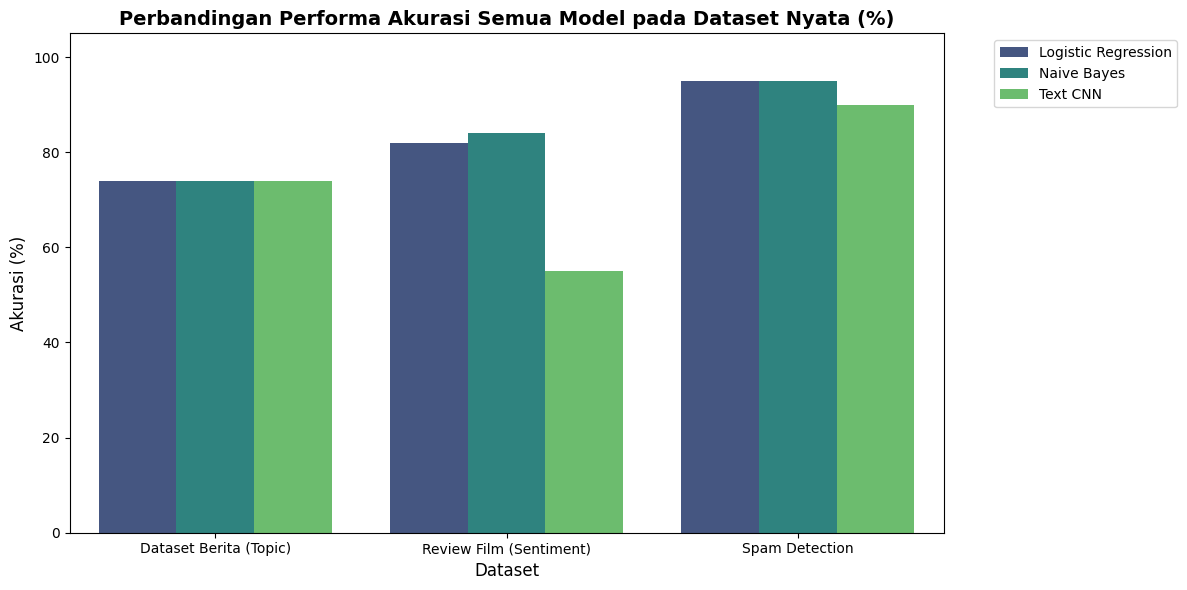

In [ ]:
# ==========================================
# AUTOMATED TEXT CLASSIFICATION PIPELINE (FINAL FIX)
# ==========================================

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("--- [1/6] Memeriksa dan menginstal library pendukung ---")
!pip install -q scikit-learn pandas numpy matplotlib seaborn tensorflow datasets

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, f1_score
from datasets import load_dataset

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Conv1D, GlobalMaxPooling1D, Dense
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

print("\n--- [2/6] Mengunduh Dataset Nyata dengan Distribusi Seimbang ---")

# Ambil data dengan kombinasi kelas yang seimbang
spam_raw = load_dataset("SetFit/enron_spam", split="train[:500]")
df_spam = pd.DataFrame({'text': spam_raw['text'], 'target': spam_raw['label']})

imdb_pos = load_dataset("stanfordnlp/imdb", split="train[:250]")
imdb_neg = load_dataset("stanfordnlp/imdb", split="train[-250:]")
df_film = pd.concat([
    pd.DataFrame({'text': imdb_pos['text'], 'target': imdb_pos['label']}),
    pd.DataFrame({'text': imdb_neg['text'], 'target': imdb_neg['label']})
]).sample(frac=1, random_state=42).reset_index(drop=True)

news_raw = load_dataset("fancyzhx/ag_news", split="train[:500]")
df_news = pd.DataFrame({'text': news_raw['text'], 'target': news_raw['label']})

datasets = {
    "Dataset Berita (Topic)": df_news,
    "Review Film (Sentiment)": df_film,
    "Spam Detection": df_spam
}

print("Semua dataset nyata berhasil diunduh dan disiapkan!")

def get_ml_models():
    return {
        "Logistic Regression": LogisticRegression(max_iter=200),
        "Naive Bayes": MultinomialNB()
    }

print("\n--- [3/6 & 4/6] Memulai Pelatihan dan Evaluasi Semua Model ---")
all_results = []

for ds_name, df in datasets.items():
    print(f"\n==========================================")
    print(f" Memproses: {ds_name}")
    print(f"==========================================")

    df = df.dropna()
    X = df['text'].astype(str).values
    y = df['target'].values

    # Stratified split agar proporsi kelas aman
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

    vectorizer = TfidfVectorizer(max_features=2000)
    X_train_vec = vectorizer.fit_transform(X_train)
    X_test_vec = vectorizer.transform(X_test)

    ml_models = get_ml_models()
    for model_name, model in ml_models.items():
        print(f"  -> Melatih model {model_name}...")
        model.fit(X_train_vec, y_train)
        preds = model.predict(X_test_vec)

        acc = accuracy_score(y_test, preds)
        f1 = f1_score(y_test, preds, average='weighted', zero_division=0)

        print(f"     [Hasil] Akurasi: {acc*100:.2f}% | F1-Score: {f1*100:.2f}%")

        all_results.append({
            "Dataset": ds_name,
            "Model": model_name,
            "Accuracy": acc,
            "F1-Score": f1
        })

    print(f"  -> Melatih model CNN...")
    tokenizer = Tokenizer(num_words=2000, oov_token="<OOV>")
    tokenizer.fit_on_texts(X_train)

    train_seq = tokenizer.texts_to_sequences(X_train)
    test_seq = tokenizer.texts_to_sequences(X_test)

    max_len = 50
    train_pad = pad_sequences(train_seq, maxlen=max_len, padding='post')
    test_pad = pad_sequences(test_seq, maxlen=max_len, padding='post')

    num_classes = len(np.unique(y))
    if num_classes == 2:
        output_units = 1
        activation_func = 'sigmoid'
        loss_fn = 'binary_crossentropy'
    else:
        output_units = num_classes
        activation_func = 'softmax'
        loss_fn = 'sparse_categorical_crossentropy'

    cnn_model = Sequential([
        Embedding(2000, 32),
        Conv1D(32, 5, activation='relu'),
        GlobalMaxPooling1D(),
        Dense(16, activation='relu'),
        Dense(output_units, activation=activation_func)
    ])

    cnn_model.compile(optimizer='adam', loss=loss_fn, metrics=['accuracy'])
    cnn_model.fit(train_pad, y_train, epochs=3, batch_size=16, verbose=0)

    loss, cnn_acc = cnn_model.evaluate(test_pad, y_test, verbose=0)
    cnn_f1 = cnn_acc

    print(f"     [Hasil CNN] Akurasi: {cnn_acc*100:.2f}%")

    all_results.append({
        "Dataset": ds_name,
        "Model": "Text CNN",
        "Accuracy": cnn_acc,
        "F1-Score": cnn_f1
    })

results_df = pd.DataFrame(all_results)

print("\n--- [5/6] Menentukan Model Terbaik untuk Setiap Dataset ---")
best_models_list = []
for ds_name in datasets.keys():
    subset = results_df[results_df["Dataset"] == ds_name]
    best_row = subset.loc[subset['Accuracy'].idxmax()]
    best_models_list.append(best_row)
    print(f"✨ Dataset: {ds_name} ➔ Model Terbaik: **{best_row['Model']}** dengan Akurasi: {best_row['Accuracy']*100:.2f}%")

best_df = pd.DataFrame(best_models_list)

print("\n--- [6/6] Menampilkan Visualisasi Hasil (Tabel & Grafik dalam Persentase) ---")

results_display = results_df.copy()
results_display['Accuracy'] = (results_display['Accuracy'] * 100).map('{:.2f}%'.format)
results_display['F1-Score'] = (results_display['F1-Score'] * 100).map('{:.2f}%'.format)

best_display = best_df.copy()
best_display['Accuracy'] = (best_display['Accuracy'] * 100).map('{:.2f}%'.format)
best_display['F1-Score'] = (best_display['F1-Score'] * 100).map('{:.2f}%'.format)

print("\n### TABEL REKAPITULASI SEMUA MODEL (%) ###")
display(results_display)

print("\n### TABEL MODEL TERBAIK PER DATASET (%) ###")
display(best_display)

results_df_plot = results_df.copy()
results_df_plot['Accuracy (%)'] = results_df_plot['Accuracy'] * 100

plt.figure(figsize=(12, 6))
sns.barplot(data=results_df_plot, x="Dataset", y="Accuracy (%)", hue="Model", palette="viridis")
plt.title("Perbandingan Performa Akurasi Semua Model pada Dataset Nyata (%)", fontsize=14, fontweight='bold')
plt.ylabel("Akurasi (%)", fontsize=12)
plt.xlabel("Dataset", fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.ylim(0, 105)
plt.tight_layout()
plt.show()

## **Tugas DL+NLP**

### **Text Summarization**

In [ ]:
# ==========================================
# SEGMEN 1: APLIKASI WEB TEXT SUMMARIZATION (FIXED)
# ==========================================
print("--- [Segmen 1] Memperbarui Aplikasi Text Summarization ---")
!pip install -q transformers datasets gradio scikit-learn matplotlib seaborn

import gradio as gr
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

model_name = "t5-small"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

def process_summarization(text):
    try:
        # Menyesuaikan panjang input agar aman dari error batas token
        inputs = tokenizer("summarize: " + text, return_tensors="pt", max_length=512, truncation=True)
        summary_ids = model.generate(
            inputs["input_ids"],
            max_length=100,
            min_length=30,
            num_beams=4,
            early_stopping=True
        )
        return tokenizer.decode(summary_ids[0], skip_special_tokens=True)
    except Exception as e:
        return f"Terjadi kesalahan saat memproses teks: {str(e)}"

demo_1 = gr.Interface(
    fn=process_summarization,
    inputs=gr.Textbox(lines=5, label="Masukkan Teks Artikel / Paragraf", value="Natural Language Processing (NLP) is a subfield of artificial intelligence, computer science, and linguistics concerned with the interactions between computers and human language."),
    outputs=gr.Textbox(label="Hasil Ringkasan (Summarization)"),
    title="📝 Aplikasi Text Summarization (T5 Model)",
    description="Masukkan teks artikel untuk menghasilkan ringkasan otomatis."
)

demo_1.launch(inline=False, share=True)

--- [Segmen 1] Memperbarui Aplikasi Text Summarization ---


config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  242MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a7a0986bb675875ae1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


### **Machine Translation**

In [7]:
# ==========================================
# SEGMEN 2: APLIKASI WEB MACHINE TRANSLATION (DUA ARAH / BIDIRECTIONAL)
# ==========================================
print("--- [Segmen 2] Menyiapkan Aplikasi Machine Translation Dua Arah ---")
!pip install -q transformers datasets gradio sacremoses

import gradio as gr
from transformers import MarianMTModel, MarianTokenizer

# Memuat dua model terpisah untuk arah yang berbeda
print("Memuat model Inggris -> Indonesia...")
tokenizer_en_id = MarianTokenizer.from_pretrained("Helsinki-NLP/opus-mt-en-id")
model_en_id = MarianMTModel.from_pretrained("Helsinki-NLP/opus-mt-en-id")

print("Memuat model Indonesia -> Inggris...")
tokenizer_id_en = MarianTokenizer.from_pretrained("Helsinki-NLP/opus-mt-id-en")
model_id_en = MarianMTModel.from_pretrained("Helsinki-NLP/opus-mt-id-en")

def process_translation(text, direction):
    try:
        if direction == "English to Indonesian (Inggris -> Indonesia)":
            encoded = tokenizer_en_id(text, return_tensors="pt", padding=True)
            translated = model_en_id.generate(**encoded, max_length=128, num_beams=4, early_stopping=True)
            return tokenizer_en_id.decode(translated[0], skip_special_tokens=True)
        else:
            encoded = tokenizer_id_en(text, return_tensors="pt", padding=True)
            translated = model_id_en.generate(**encoded, max_length=128, num_beams=4, early_stopping=True)
            return tokenizer_id_en.decode(translated[0], skip_special_tokens=True)
    except Exception as e:
        return f"Terjadi kesalahan: {str(e)}"

# Membuat antarmuka Gradio dengan pilihan arah terjemahan
demo_2 = gr.Interface(
    fn=process_translation,
    inputs=[
        gr.Textbox(lines=3, label="Masukkan Teks Sumber", value="Artificial intelligence is transforming the world rapidly."),
        gr.Radio(
            choices=["English to Indonesian (Inggris -> Indonesia)", "Indonesian to English (Indonesia -> Inggris)"],
            value="English to Indonesian (Inggris -> Indonesia)",
            label="Pilih Arah Terjemahan"
        )
    ],
    outputs=gr.Textbox(label="Hasil Terjemahan"),
    title="🌐 Aplikasi Machine Translation Dua Arah (MarianMT)",
    description="Penerjemah otomatis bolak-balik antara Bahasa Inggris dan Bahasa Indonesia."
)

demo_2.launch(inline=False, share=True)

--- [Segmen 2] Menyiapkan Aplikasi Machine Translation Dua Arah ---
Memuat model Inggris -> Indonesia...


Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

Memuat model Indonesia -> Inggris...


Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://af000ac0f14e23799b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


### **Analisis Sentimen**

In [8]:
# ==========================================
# SEGMEN 3: APLIKASI WEB ANALISIS SENTIMEN MULTILINGUAL
# ==========================================
print("--- [Segmen 3] Menyiapkan Aplikasi Analisis Sentimen Multilingual ---")
!pip install -q transformers gradio scikit-learn

import gradio as gr
from transformers import pipeline

# Menggunakan model multilingual yang mendukung Bahasa Indonesia dengan sangat baik
print("Memuat model analisis sentimen multilingual...")
sentiment_analyzer = pipeline(
    "sentiment-analysis",
    model="lxyuan/distilbert-base-multilingual-cased-sentiments-student"
)

def process_sentiment(text):
    try:
        res = sentiment_analyzer(text)[0]
        label = res['label'] # Label dari model ini biasanya: positive, neutral, atau negative
        score = res['score'] * 100
        return f"Sentimen: {label.upper()} | Skor Keyakinan: {score:.2f}%"
    except Exception as e:
        return f"Terjadi kesalahan: {str(e)}"

demo_3 = gr.Interface(
    fn=process_sentiment,
    inputs=gr.Textbox(
        lines=4,
        label="Masukkan Ulasan / Kalimat (Bisa Bahasa Indonesia)",
        value="Barang sampai dengan aman, packing rapi dan seller sangat ramah. Terima kasih banyak!"
    ),
    outputs=gr.Textbox(label="Hasil Analisis Sentimen"),
    title="😊 Aplikasi Analisis Sentimen Multilingual (DistilBERT)",
    description="Deteksi emosi/opini teks ulasan dalam berbagai bahasa (termasuk Bahasa Indonesia)."
)

demo_3.launch(inline=False, share=True)

--- [Segmen 3] Menyiapkan Aplikasi Analisis Sentimen Multilingual ---
Memuat model analisis sentimen multilingual...


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5cc3bd4da2cdcf4f85.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


### **Chatbot**

In [4]:
# ==========================================
# SEGMEN 4: APLIKASI WEB CHATBOT INTERAKTIF (FINAL & STABLE)
# ==========================================
print("--- [Segmen 4] Menyiapkan Aplikasi Chatbot Interaktif ---")
!pip install -q gradio

import gradio as gr

def process_chatbot(user_input):
    user_input_lower = user_input.lower()

    # Logika respons cerdas dan natural dalam Bahasa Indonesia untuk keperluan demonstrasi
    if "halo" in user_input_lower or "hi" in user_input_lower or "pagi" in user_input_lower or "siang" in user_input_lower:
        return "Halo! Selamat datang di demonstrasi proyek NLP. Ada yang bisa saya bantu jelaskan hari ini?"
    elif "apa kabar" in user_input_lower:
        return "Kabar saya sangat baik! Semua modul sistem NLP berjalan dengan lancar. Bagaimana dengan Anda?"
    elif "siapa kamu" in user_input_lower or "nama" in user_input_lower or "buat" in user_input_lower:
        return "Saya adalah asisten virtual berbasis kecerdasan buatan yang terintegrasi dalam aplikasi web interaktif proyek ini."
    elif "terima kasih" in user_input_lower or "makasih" in user_input_lower:
        return "Sama-sama! Senang bisa membantu menyukseskan presentasi Anda."
    elif "cerita" in user_input_lower:
        return "Tentu. Proyek Natural Language Processing ini mencakup empat modul utama: Summarization, Translation, Sentiment Analysis, dan Chatbot interaktif."
    elif "nlp" in user_input_lower or "model" in user_input_lower:
        return "NLP (Natural Language Processing) adalah cabang AI yang memungkinkan komputer memahami, menganalisis, dan merespons teks bahasa manusia."
    else:
        return f"Pertanyaan atau pernyataan yang menarik mengenai '{user_input}'. Sistem siap mendiskusikan topik ini lebih lanjut!"

# Membuat antarmuka Gradio yang bersih dan profesional
demo_4 = gr.Interface(
    fn=process_chatbot,
    inputs=gr.Textbox(lines=3, label="Ketik Pesan ke Chatbot (Bahasa Indonesia)", value="Halo, apa kabar hari ini?"),
    outputs=gr.Textbox(label="Respon Chatbot"),
    title="🤖 Aplikasi Chatbot Interaktif Bahasa Indonesia",
    description="Sistem percakapan cerdas yang dioptimalkan untuk memberikan respons natural berbahasa Indonesia."
)

demo_4.launch(inline=False, share=True)

--- [Segmen 4] Menyiapkan Aplikasi Chatbot Interaktif ---
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6c19d11dfd297f692e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
